# 1. Pricing

Short tour of the pricing side of `mc-risk`: European options and variance reduction, exotics, and the Heston and Merton models. Every Monte Carlo number is shown next to an independent reference. The full checks are in `docs/validation.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mc_risk import (
    price_american_lsm, price_asian, price_down_and_out_call, price_european,
    price_european_heston, price_european_merton, variance_reduction_factor,
)
from mc_risk.analytic import (
    bgk_adjusted_barrier, bs_price, crr_price, down_and_out_call, heston_price, merton_price,
)

pd.options.display.float_format = '{:.5f}'.format
BASE = dict(s0=100.0, k=105.0, r=0.03, sigma=0.2, t=1.0, q=0.01)

## European call: four sampling methods against Black-Scholes

Same budget of 2^17 paths for each method. The variance reduction factor (VRF) is the variance of plain Monte Carlo over the variance of the method.

In [2]:
ref = bs_price(**BASE)
runs = {m: price_european(**BASE, n_paths=2**17, method=m, seed=0) for m in ('plain', 'antithetic', 'control', 'sobol')}
pd.DataFrame({
    'price': {m: r.price for m, r in runs.items()},
    'error': {m: r.price - ref for m, r in runs.items()},
    'std_error': {m: r.std_error for m, r in runs.items()},
    'VRF': {m: variance_reduction_factor(runs['plain'], r) for m, r in runs.items()},
    'inside 99% CI': {m: r.contains(ref) for m, r in runs.items()},
})

,price,error,std_error,VRF,inside 99% CI
plain,6.63955,0.00149,0.03337,1.00000,True
antithetic,6.63307,-0.00499,0.02787,1.43384,True
control,6.64386,0.00580,0.01673,3.97940,True
sobol,6.63779,-0.00028,0.00061,3018.40735,True


## Convergence

Plain Monte Carlo error falls like $1/\sqrt{N}$. Randomised Sobol falls faster for this smooth one-dimensional problem.

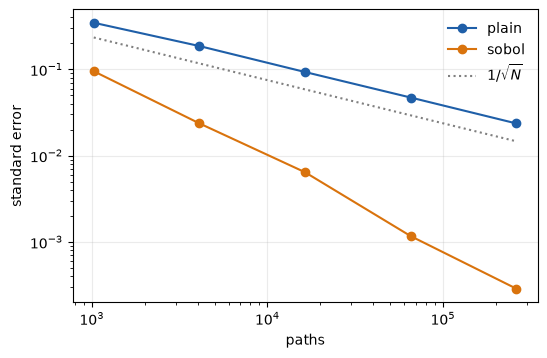

In [3]:
ns = [2**p for p in range(10, 19, 2)]
fig, ax = plt.subplots(figsize=(6, 3.8))
for method, colour in (('plain', '#1f5fa8'), ('sobol', '#d9730d')):
    se = [price_european(**BASE, n_paths=n, method=method, seed=0).std_error for n in ns]
    ax.loglog(ns, se, 'o-', color=colour, label=method)
ax.loglog(ns, 0.75 / np.sqrt(ns) * 10, ':', color='grey', label=r'$1/\sqrt{N}$')
ax.set_xlabel('paths'); ax.set_ylabel('standard error'); ax.legend(frameon=False); ax.grid(alpha=0.25)
plt.show()

## Exotics

- Arithmetic Asian with the geometric Asian as control variate.
- Down-and-out call: discrete monitoring against the continuous closed form, with and without the Broadie-Glasserman-Kou correction.
- American put by Longstaff-Schwartz against a CRR tree with the same 50 exercise dates.

In [4]:
A = dict(s0=100.0, k=100.0, r=0.03, sigma=0.2, t=1.0, q=0.01)
plain = price_asian(**A, n_steps=50, control_variate=False, seed=0)
cv = price_asian(**A, n_steps=50, seed=0)
print(f'Asian plain   {plain.price:.4f} +/- {plain.std_error:.4f}')
print(f'Asian with CV {cv.price:.4f} +/- {cv.std_error:.5f}   VRF {variance_reduction_factor(plain, cv):,.0f}x')

Asian plain   5.0712 +/- 0.0241
Asian with CV 5.0785 +/- 0.00064   VRF 1,413x


In [5]:
s0, k, h, r, sigma, t, q = 100.0, 100.0, 90.0, 0.03, 0.2, 1.0, 0.01
rows = []
for m in (12, 52, 252):
    mc = price_down_and_out_call(s0, k, h, r, sigma, t, q=q, n_monitor=m, n_paths=200_000, seed=0)
    rows.append(dict(monitoring_dates=m, mc=mc.price, std_error=mc.std_error,
                     continuous_formula=down_and_out_call(s0, k, h, r, sigma, t, q),
                     bgk_corrected=down_and_out_call(s0, k, bgk_adjusted_barrier(h, sigma, t, m), r, sigma, t, q)))
pd.DataFrame(rows).set_index('monitoring_dates')

,mc,std_error,continuous_formula,bgk_corrected
monitoring_dates,,,,
12,8.06158,0.03052,7.22781,8.03663
52,7.64943,0.03023,7.22781,7.67517
252,7.44721,0.03012,7.22781,7.44603


In [6]:
P = dict(s0=36.0, k=40.0, r=0.06, sigma=0.2, t=1.0)
lsm = price_american_lsm(**P, n_steps=50, n_paths=100_000, seed=0)
print(f'LSM              {lsm.price:.4f} +/- {lsm.std_error:.4f}')
print(f'CRR Bermudan-50  {crr_price(**P, n_steps=2000, exercise_every=40):.4f}')
print(f'CRR American     {crr_price(**P, n_steps=2000):.4f}')
print(f'European (BS)    {bs_price(**P, option="put"):.4f}')

LSM              4.4839 +/- 0.0093
CRR Bermudan-50  4.4780
CRR American     4.4867
European (BS)    3.8443


## Heston and Merton

Heston is simulated with full-truncation Euler, so it has a discretisation bias that the confidence interval does not see. Merton is simulated exactly.

In [7]:
H = dict(s0=100.0, k=100.0, v0=0.04, r=0.03, kappa=1.5, theta=0.04, xi=0.6, rho=-0.7, t=1.0)
ref = heston_price(**H)
rows = []
for n in (4, 16, 64, 256):
    mc = price_european_heston(**H, n_steps=n, n_paths=1_000_000, seed=0)
    rows.append(dict(steps=n, mc=mc.price, bias=mc.price - ref, std_error=mc.std_error, inside_ci=mc.contains(ref)))
print(f'semi-analytic reference: {ref:.5f}')
pd.DataFrame(rows).set_index('steps')

semi-analytic reference: 8.58190


,mc,bias,std_error,inside_ci
steps,,,,
4,9.34883,0.76693,0.01130,False
16,8.72290,0.14100,0.00981,False
64,8.59784,0.01594,0.00957,True
256,8.58583,0.00393,0.00954,True


In [8]:
M = dict(s0=100.0, k=100.0, r=0.03, sigma=0.15, lam=0.5, mu_j=-0.1, delta=0.15, t=1.0)
mc = price_european_merton(**M, n_paths=400_000, seed=0)
print(f'Merton MC     {mc.price:.4f} +/- {mc.std_error:.4f}')
print(f'Merton series {merton_price(**M):.4f}   inside 99% CI: {mc.contains(merton_price(**M))}')

Merton MC     8.9848 +/- 0.0199
Merton series 8.9862   inside 99% CI: True
